# Week 2 - Histograms with segmentation
Necessary imports

In [1]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from scipy.ndimage import gaussian_filter1d, binary_fill_holes, gaussian_filter1d

In [2]:
def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [3]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [4]:
train_dataset = load_image_dataset(f"{DATA_DIR}/BBDD")
ground_truth = load_ground_truth(f"{DATA_DIR}/qsd1_w1/gt_corresps.pkl")

## Task 1. Simple image segmentation and histogramization

Simple pyramid segmentation which splits an (HxW) image onto NxN blocks of size (W/N, H/N). Histograms are computed on normalized lab space as in the last week code and normalized before being concatenated onto a 1D $b*N^2*3$ size vector (b being the bin size)

In [5]:
def simple_segment_and_histogram(img, level, bins=48, plot=False, normalize=True, weights=None):
    
    """
    Segment a BGR image into a level x level grid and compute
    concatenated L, A, B histograms for every block.

    Returns
    -------
    np.ndarray
        Flattened array of length level * level * 3 * bins
        (reshape to (level * level, 3 * bins) to get one row per block).
    """

    h, w = img.shape[:2]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

    histograms = np.empty((level * level, 3 * bins), dtype=np.float32)

    y_edges = np.linspace(0, h, level + 1, dtype=int)
    x_edges = np.linspace(0, w, level + 1, dtype=int)

    for i in range(level):
        for j in range(level):
            idx = i * level + j
            block = lab[y_edges[i]:y_edges[i + 1],
                        x_edges[j]:x_edges[j + 1]]

            channel_histograms = []
            for channel in range(3):
                hist = cv2.calcHist([block], [channel], None,
                                    [bins], [0, 256]).ravel()
                if normalize:
                    hist /= max(hist.sum(), 1e-12)
                channel_histograms.append(hist)

            histograms[idx] = np.concatenate(channel_histograms)

    if plot:
        fig = plt.figure(figsize=(4 * (level + 1), 2.8 * level),
                         layout="constrained")
        outer = fig.add_gridspec(1, 2, width_ratios=[1, level])

        # ---- Left: image with the segmentation grid ----
        ax_img = fig.add_subplot(outer[0])
        ax_img.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

        # Block boundaries sit between pixels, hence the -0.5 offset.
        for x in x_edges[1:-1]:
            ax_img.axvline(x - 0.5, color="red", linewidth=1.5)
        for y in y_edges[1:-1]:
            ax_img.axhline(y - 0.5, color="red", linewidth=1.5)

        # Label each block at its center.
        for i in range(level):
            for j in range(level):
                cx = (x_edges[j] + x_edges[j + 1]) / 2
                cy = (y_edges[i] + y_edges[i + 1]) / 2
                ax_img.text(cx, cy, f"({i},{j})", color="white",
                            ha="center", va="center", fontsize=9,
                            bbox=dict(facecolor="black", alpha=0.5,
                                      edgecolor="none", pad=1.5))

        ax_img.set_title(f"Segmentation ({level}x{level} blocks)")
        ax_img.axis("off")

        # ---- Right: one histogram plot per block ----
        inner = outer[1].subgridspec(level, level)
        channel_names = ["L", "a", "b"]
        channel_colors = ["black", "green", "blue"]

        for i in range(level):
            for j in range(level):
                idx = i * level + j
                ax = fig.add_subplot(inner[i, j])

                for c, (name, color) in enumerate(
                        zip(channel_names, channel_colors)):
                    start, end = c * bins, (c + 1) * bins
                    ax.plot(np.arange(start, end),
                            histograms[idx, start:end],
                            color=color, linewidth=1.3, label=name)

                ax.axvline(bins - 0.5, color="gray",
                           linestyle="--", linewidth=0.8)
                ax.axvline(2 * bins - 0.5, color="gray",
                           linestyle="--", linewidth=0.8)

                ax.set_title(f"Block ({i}, {j})", fontsize=10)
                ax.set_xlim(0, 3 * bins - 1)
                ax.set_xticks([bins / 2 - 0.5,
                               1.5 * bins - 0.5,
                               2.5 * bins - 0.5])
                ax.set_xticklabels(channel_names)
                ax.grid(alpha=0.2)

                if j == 0:
                    ax.set_ylabel("Frequency" if normalize
                                  else "Pixel count")
                if i == 0 and j == level - 1:
                    ax.legend(fontsize=8, loc="upper right")

        plt.show()

    return histograms.flatten()

### Tests on images
To ensure that the image segmentation and histogramisation is going correctly, some tests and plotting are done on arbitrary images

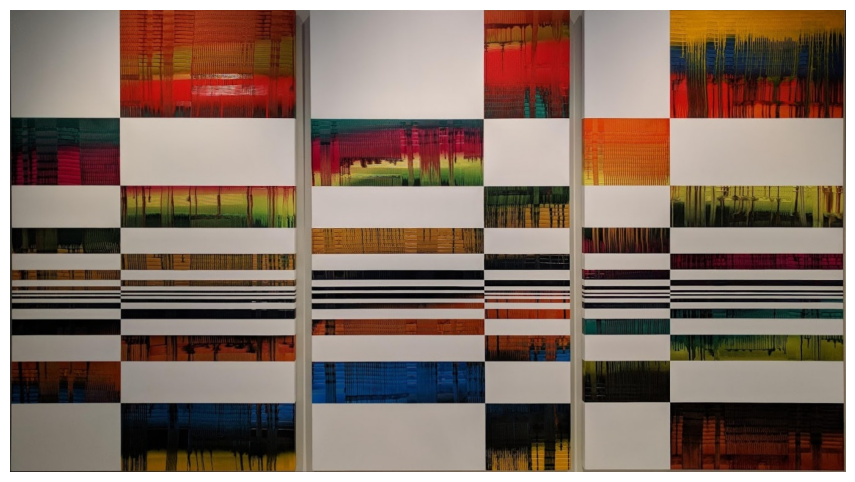

In [6]:
image = cv2.imread(train_dataset.paths[0].as_posix())
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


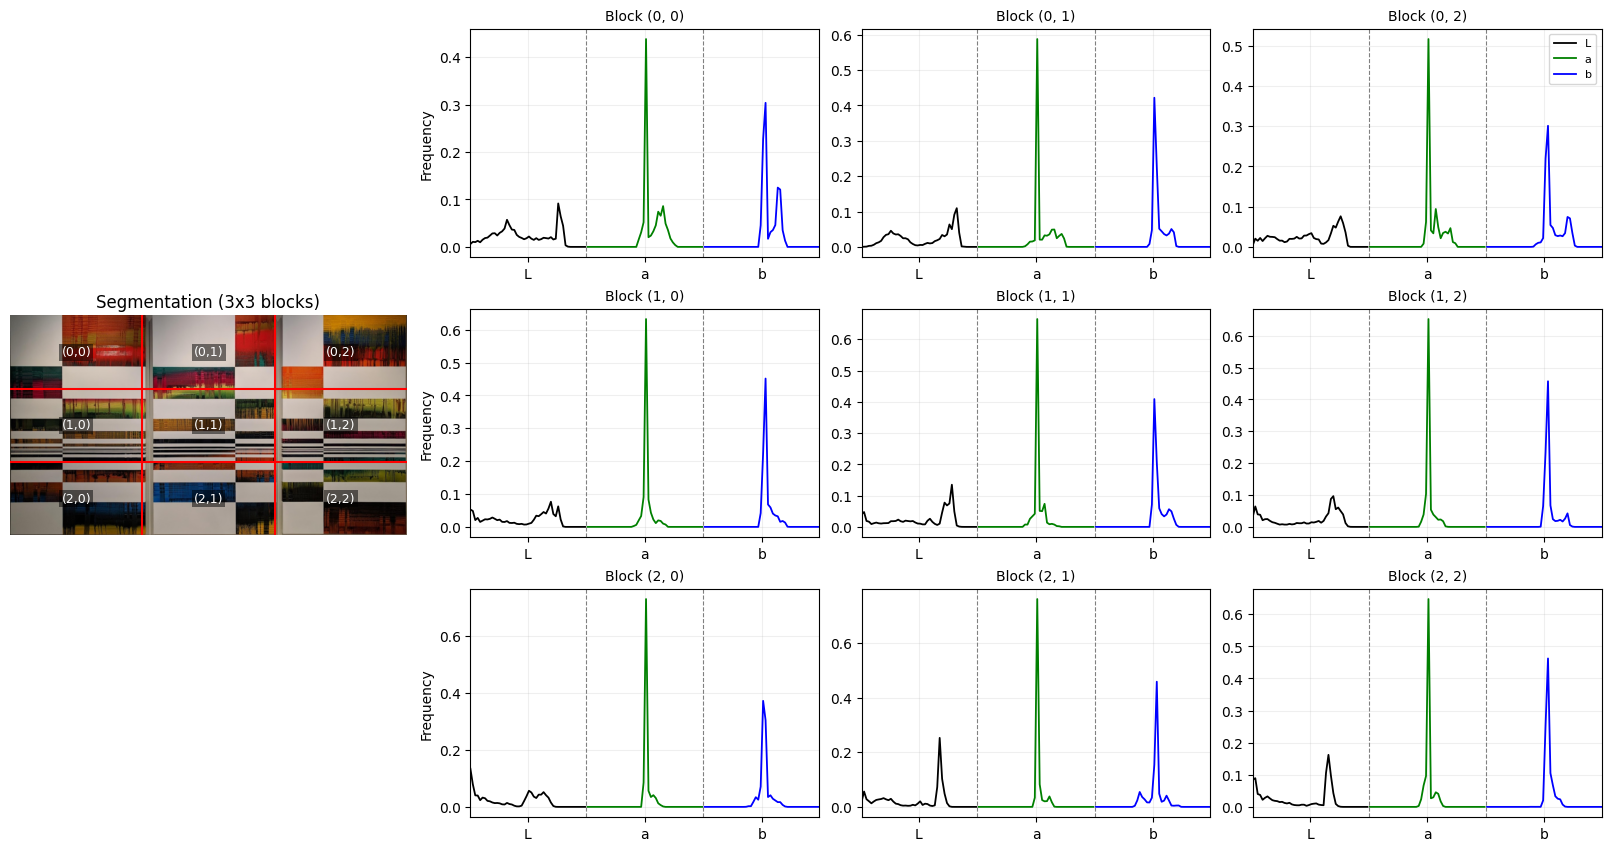

In [7]:
test_hist = simple_segment_and_histogram(image, level=3, plot=True)

In [8]:
test_hist.shape

(1296,)

## Task 2 - Query system with block histograms

We run the same 30 development queries (QSD1-W2 is the same set as QSD1-W1) using the block histograms from Task 1, measure mAP@1 and mAP@5, and compare with our best W1 result (global tuned Lab histogram, Hellinger: mAP@1 0.700, mAP@5 0.728).

In [9]:
query_dataset = load_image_dataset(f"{DATA_DIR}/qsd1_w1")      
read = lambda p: cv2.imread(p.as_posix())
q_imgs  = [read(p) for p in query_dataset.paths]
db_imgs = [read(p) for p in train_dataset.paths]
print(len(db_imgs), len(q_imgs), len(ground_truth))       

287 30 30


### Distance and evaluation
Same as W1: Hellinger distance (the best measure in W1) and mAP@K. Each query has one correct painting, so AP@K = 1/rank if it appears in the top K, and 0 otherwise.

In [10]:
def hellinger(q, D):
    return np.sqrt(((np.sqrt(q) - np.sqrt(D)) ** 2).sum(axis=1))

def map_at_k(results, gt, k):
    aps = []
    for res, rel in zip(results, gt):
        ap, hits = 0.0, 0
        for r, img_id in enumerate(res[:k], start=1):
            if img_id in rel:
                hits += 1
                ap += hits / r
        aps.append(ap / min(len(rel), k))
    return float(np.mean(aps))

### Block histograms with the W1 descriptor
We use the best descriptor from W1: Lab, 48 bins per channel, Gaussian smoothing along the bins (σ 0.5), channel weights (L, a, b = 0.125, 0.5, 0.375) and Hellinger distance. Now it is computed per block: the image is split into N×N blocks, each block gets its own histograms, and they are concatenated. The argument `levels` also lets us join several grid levels (spatial pyramid) in one descriptor.

The 1x1 grid is the W1 global histogram, so its result must match W1 (mAP@1 0.700, mAP@5 0.728). This checks the pipeline, and every other row is compared with it.

In [11]:
def descriptor(img, levels=(1,), bins=48, sigma=0.5, weights=(0.125, 0.5, 0.375)):
    out = []
    for level in levels:
        h = simple_segment_and_histogram(img, level, bins=bins).reshape(level*level, 3, bins)
        if sigma > 0:
            h = gaussian_filter1d(h, sigma, axis=2, mode="nearest")   # smooth along the bins
            h = h / h.sum(axis=2, keepdims=True)                      # normalise each channel again
        h = h * np.asarray(weights)[None, :, None]                    # L, a, b weights
        out.append(h.ravel() / h.sum())
    return np.concatenate(out) / len(levels)

### Which grid size works best?
We test grids from 1x1 (the W1 global histogram) to 6x6, and two pyramids (several levels joined). All use Hellinger.

In [12]:
configs = {"global (1)": (1,), "2x2": (2,), "3x3": (3,), "4x4": (4,),
           "5x5": (5,), "6x6": (6,),
           "pyramid 1-2": (1, 2), "pyramid 1-2-3": (1, 2, 3)}
rows, store = [], {}
for name, lv in configs.items():
    D = np.array([descriptor(im, lv) for im in db_imgs])
    res = [[int(train_dataset.ids[i]) for i in np.argsort(hellinger(descriptor(im, lv), D), kind="stable")[:10]]
           for im in q_imgs]
    rows.append((name, map_at_k(res, ground_truth, 1), map_at_k(res, ground_truth, 5)))
    store[name] = res
    print(f"{name:<14} mAP@1 {rows[-1][1]:.3f}   mAP@5 {rows[-1][2]:.3f}")

global (1)     mAP@1 0.700   mAP@5 0.728
2x2            mAP@1 0.700   mAP@5 0.767
3x3            mAP@1 0.800   mAP@5 0.843
4x4            mAP@1 0.833   mAP@5 0.867
5x5            mAP@1 0.867   mAP@5 0.892
6x6            mAP@1 0.867   mAP@5 0.892
pyramid 1-2    mAP@1 0.667   mAP@5 0.754
pyramid 1-2-3  mAP@1 0.700   mAP@5 0.778


### Results
The `global (1)` row reproduces our W1 result (0.700 / 0.728), so the rows below are directly comparable with it.

| descriptor | mAP@1 | mAP@5 |
|---|---|---|
| global (W1) | 0.700 | 0.728 |
| 2x2 | 0.700 | 0.767 |
| 3x3 | 0.800 | 0.843 |
| 4x4 | 0.833 | 0.867 |
| **5x5** | **0.867** | **0.892** |
| 6x6 | 0.867 | 0.892 |
| pyramid 1-2 | 0.667 | 0.754 |
| pyramid 1-2-3 | 0.700 | 0.778 |

- Block histograms are better than the global histogram: mAP@1 goes from 0.700 to 0.867 with 5x5 blocks (5 more queries correct out of 30). A global histogram only tells which colours are in the painting. Blocks also tell where they are.
- The improvement stops at 5x5: 6x6 gives the same result, so we choose **5x5** (3,600 values per image, instead of 5,184).
- Pyramids are not better than a single fine grid. The coarse levels dilute the spatial detail.
- Caution: the grid size was chosen on the same 30 queries, and 4x4, 5x5 and 6x6 differ by only one query each. So we only claim that blocks help and that results plateau around 5x5, not that 5x5 is clearly better than 4x4.

### Examples of retrieval (5x5)
For each query we show the top 5 results. Green border = correct painting, red = wrong.

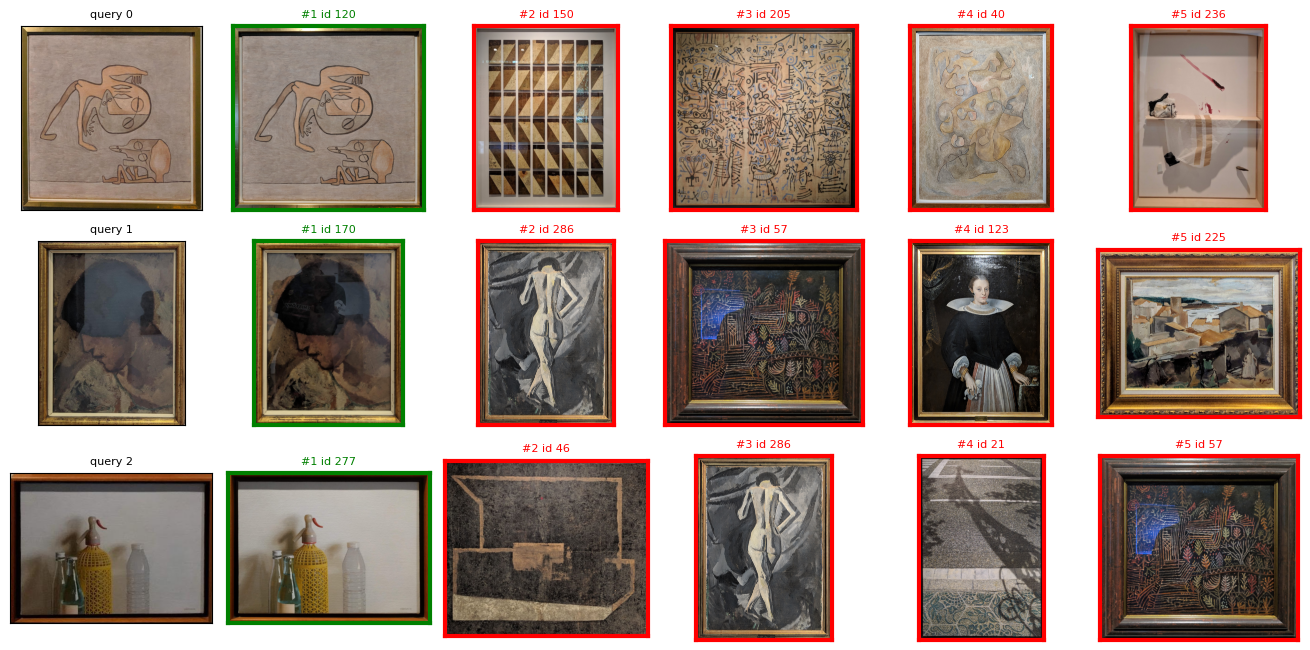

In [13]:
def show_retrievals(res, q_imgs, db_imgs, db_ids, gt, query_ids, k=5):
    id2 = {int(i): n for n, i in enumerate(db_ids)}
    fig, axes = plt.subplots(len(query_ids), k + 1, figsize=(2.2*(k+1), 2.2*len(query_ids)))
    axes = np.atleast_2d(axes)
    for r, qi in enumerate(query_ids):
        axes[r, 0].imshow(cv2.cvtColor(q_imgs[qi], cv2.COLOR_BGR2RGB))
        axes[r, 0].set_title(f"query {qi}", fontsize=8)
        for c, img_id in enumerate(res[qi][:k], 1):
            axes[r, c].imshow(cv2.cvtColor(db_imgs[id2[img_id]], cv2.COLOR_BGR2RGB))
            col = "green" if img_id in gt[qi] else "red"
            axes[r, c].set_title(f"#{c} id {img_id}", fontsize=8, color=col)
            for s in axes[r, c].spines.values():
                s.set_edgecolor(col); s.set_linewidth(3)
        for a in axes[r]:
            a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

show_retrievals(store["5x5"], q_imgs, db_imgs, train_dataset.ids, ground_truth, [0, 1, 2])

### Failure analysis
We look at the queries where the correct painting is not at rank 1 with the 5x5 descriptor.

In [14]:
best = "5x5"
fails = []
for i, (res, gt) in enumerate(zip(store[best], ground_truth)):
    pos = next((r for r, img_id in enumerate(res, 1) if img_id in gt), None)   # None = not in top 10
    if pos != 1:
        fails.append(i)
        print(f"query {i:>2}  gt id {gt[0]:>3}  correct image at rank: {pos}")
print("\nfailing at rank 1:", len(fails), "of", len(ground_truth))

query  5  gt id 274  correct image at rank: None
query 17  gt id  47  correct image at rank: 2
query 26  gt id 238  correct image at rank: 4
query 28  gt id  86  correct image at rank: None

failing at rank 1: 4 of 30


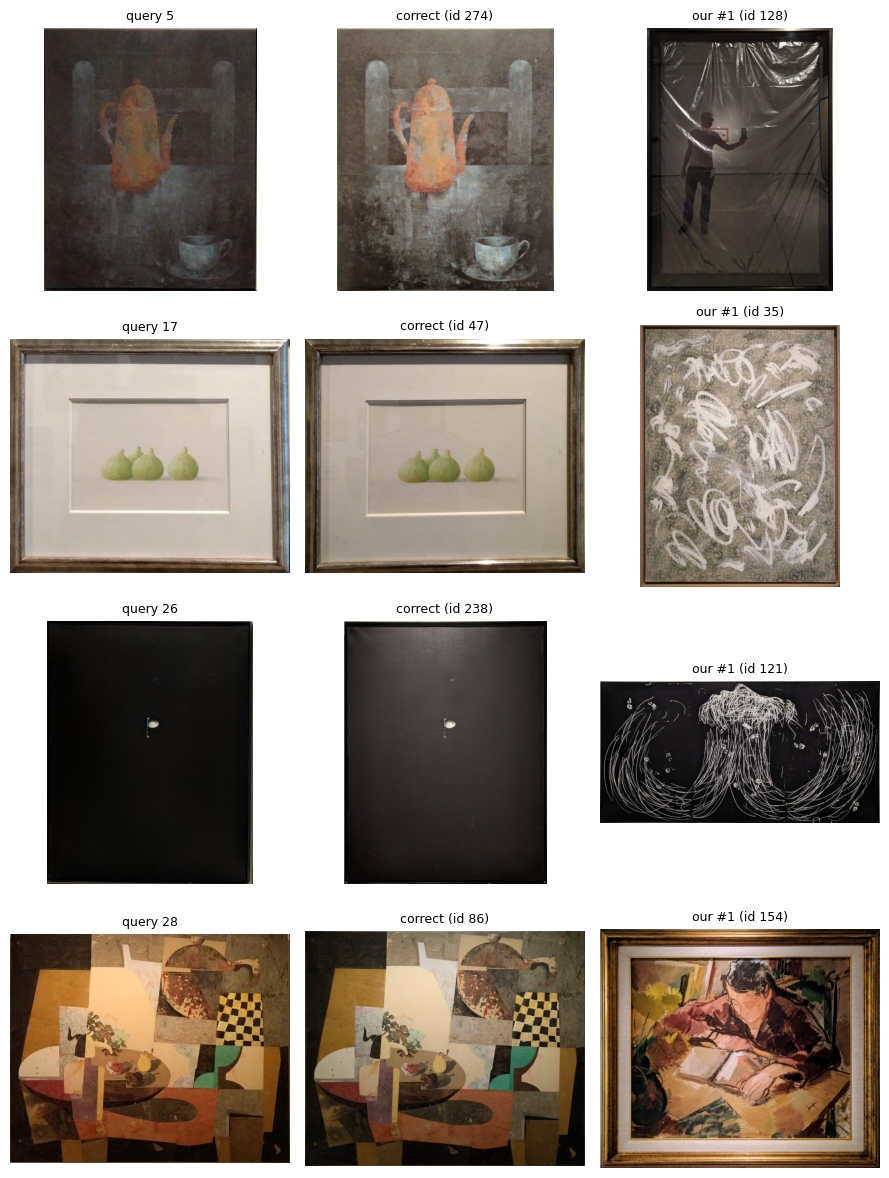

In [15]:
id2 = {int(i): n for n, i in enumerate(train_dataset.ids)}
fig, axes = plt.subplots(len(fails[:4]), 3, figsize=(9, 3 * len(fails[:4])))
axes = np.atleast_2d(axes)
for r, qi in enumerate(fails[:4]):
    wrong_id = store[best][qi][0]
    for c, (img, title) in enumerate([
            (q_imgs[qi], f"query {qi}"),
            (db_imgs[id2[ground_truth[qi][0]]], f"correct (id {ground_truth[qi][0]})"),
            (db_imgs[id2[wrong_id]], f"our #1 (id {wrong_id})")]):
        axes[r, c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[r, c].set_title(title, fontsize=9); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

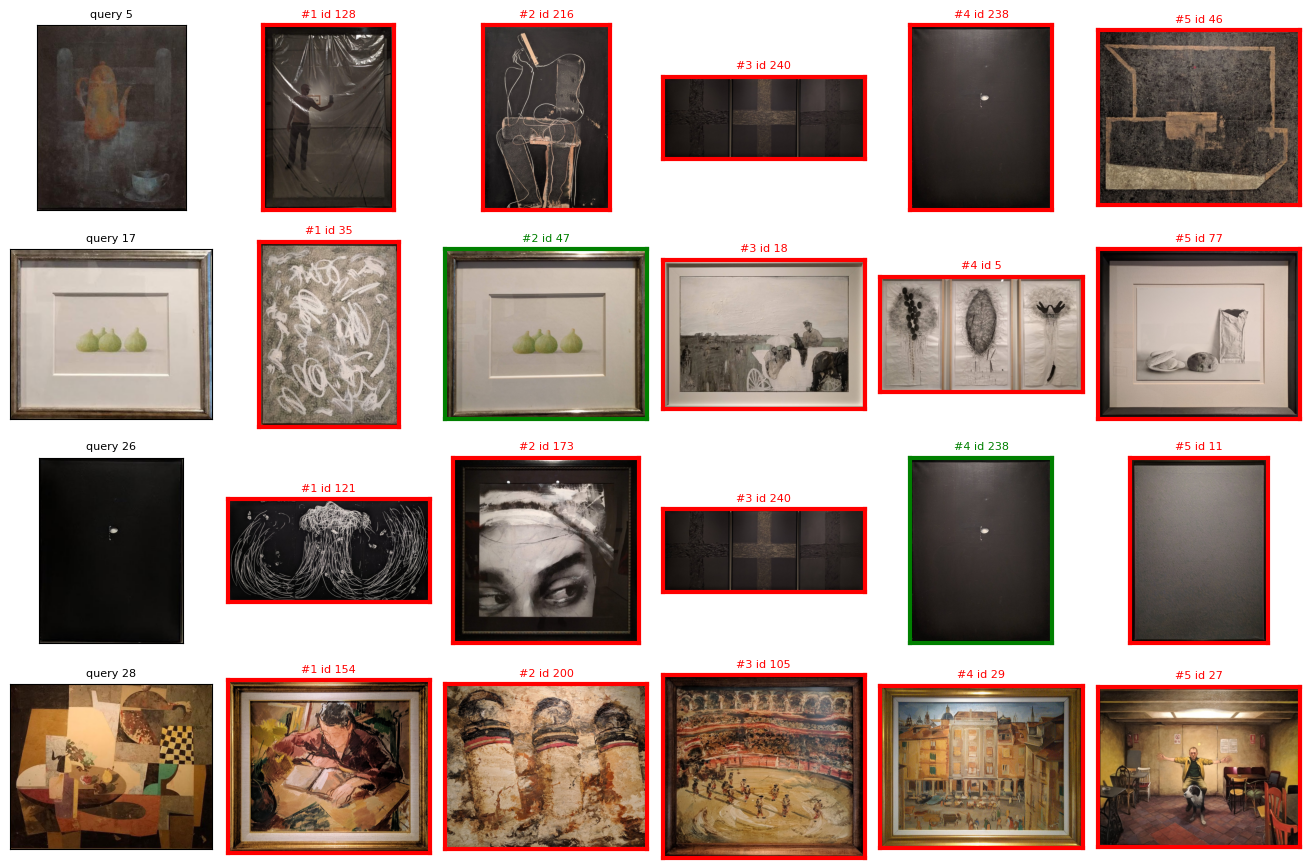

In [16]:
show_retrievals(store[best], q_imgs, db_imgs, train_dataset.ids, ground_truth, fails[:4])

Main causes: (1) colour and lighting differ between the query photo and the database photo, and histograms compare colour values directly; (2) dark paintings fall into the same few low-L bins; (3) the frame and the wall count as painting content. This motivates colour normalisation and background removal (Task 3) as the next steps.


Conclusion (Task 2): Block histograms (5x5, Lab, σ 0.5, weighted channels, Hellinger) improve our W1 result from mAP@1 0.700 / mAP@5 0.728 to 0.867 / 0.892 on QSD1. The gain comes from adding spatial information. The remaining errors come mainly from lighting changes and from frames or background in the photo.

## Task 3 - Removing background

Remove all the backgrounds of the images of /QST2_W2 using the background color (e.g. model background distribution, color
thresholds, …)

The implemented idea is:
1. Take a strip along the outer border of the image (4 % of the shorter side), which most likely belongs to the background.
2. Work with LAB hist but give less weight to lightness (L: 0.5). Lighting varies across a wall (gradients, shadows, exposure), whereas the wall colour does not.
3. Run k-means (k = 3) on the border pixels. The largest cluster is taken as the background colour. The other clusters are kept only if they cover at least 25 % of the border (e.g. a floor).
4. Model each kept cluster by its mean and its per-channel standard deviation.
5. For every pixel of the image, compute the weighted z-score distance to the closest background cluster.
6. Threshold this distance (Otsu on the log distance, clipped to [2, 6]). Pixels close to the background model are background and the rest are foreground.
7. Keep as background only the regions connected to the image border, so that wall-coloured areas inside the painting remain in the foreground.
8. Clean the mask (opening, closing, hole filling, removal of blobs smaller than 5 % of the image).
9. Compute the descriptor on the foreground pixels only (crop to the mask bounding box, masked histograms).

In [17]:
def border_strips(h, w, frac):
    """
    Step 1: marks the outer strip of the image, which most likely belongs to the background.

    Returns
    -------
    np.ndarray
        Boolean array of shape (h, w), True on a strip of width max(3, round(frac * min(h, w)))
        along the four image borders.
    """
    bw = max(3, int(round(frac * min(h, w))))
    m = np.zeros((h, w), bool)
    m[:bw], m[-bw:], m[:, :bw], m[:, -bw:] = True, True, True, True
    return m


def background_distance(lab, border, k=3, min_share=0.25, w_lab=(0.5, 1.0, 1.0), sigma_floor=(2.5, 1.5, 1.5)):
    """
    Steps 2-5: fits the background colour model on the border pixels (L-weighted k-means, mean and std per 
    cluster) and measures every pixel's distance to it.

    Returns
    -------
    np.ndarray
        Float32 array of shape (h, w) with the weighted z-score distance of each pixel to the
        closest kept background cluster (small = background-like).
    """
    wv = np.asarray(w_lab, np.float32)
    X = lab[border]
    K = min(k, len(X))
    cv2.setRNGSeed(0)                                    # deterministic
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    _, idx, _ = cv2.kmeans((X * wv).astype(np.float32), K, None, crit, 3,
                           cv2.KMEANS_PP_CENTERS)
    idx = idx.ravel()
    share = np.bincount(idx, minlength=K) / len(X)
    keep = [c for c in range(K) if share[c] >= min_share or c == share.argmax()]

    flat = lab.reshape(-1, 3)
    dist = np.full(flat.shape[0], np.inf, np.float32)
    for c in keep:
        pts = X[idx == c]
        mu = pts.mean(0)
        sd = np.maximum(pts.std(0), sigma_floor)
        d = np.sqrt((((flat - mu) / sd * wv) ** 2).sum(1))
        dist = np.minimum(dist, d)
    return dist.reshape(lab.shape[:2])


def adaptive_threshold(dist, tau_range=(2.0, 6.0)):
    """
    Step 6: chooses the background/foreground distance threshold with Otsu on log(1 + distance),
    clipped to tau_range.

    Returns
    -------
    float
        Threshold tau, in distance units and within tau_range; pixels with distance < tau
        are background candidates.
    """
    dmax = max(float(dist.max()), 1.0)
    scaled = np.clip(np.log1p(dist) / np.log1p(dmax) * 255, 0, 255).astype(np.uint8)
    t, _ = cv2.threshold(scaled, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tau = np.expm1(t / 255 * np.log1p(dmax))
    return float(np.clip(tau, *tau_range))


def foreground_mask(img, work_size=400, border_frac=0.04, k=3, min_share=0.25,
                    w_lab=(0.5, 1.0, 1.0), sigma_floor=(2.5, 1.5, 1.5),
                    tau_range=(2.0, 6.0), morph_frac=0.012, min_area=0.05,
                    keep="all", rectangular=False, return_debug=False):
    """
    Steps 1-8: computes the colour-only binary foreground (painting) mask of 
    a BGR image, from background model to mask clean-up.

    Returns
    -------
    np.ndarray
        Boolean array of shape (H, W) (original image size), True on foreground pixels.
        If return_debug is True, returns (mask, dict(dist, tau, border)) instead.
    """
    H, W = img.shape[:2]
    s = min(1.0, work_size / max(H, W))
    small = cv2.resize(img, (max(1, round(W * s)), max(1, round(H * s))),
                       interpolation=cv2.INTER_AREA) if s < 1 else img
    small = cv2.GaussianBlur(small, (5, 5), 0)
    lab = cv2.cvtColor(small.astype(np.float32) / 255.0, cv2.COLOR_BGR2LAB)  # L 0..100, a/b ~ -127..127
    h, w = lab.shape[:2]

    border = border_strips(h, w, border_frac)
    dist = background_distance(lab, border, k, min_share, w_lab, sigma_floor)
    tau = adaptive_threshold(dist, tau_range)

    bg = (dist < tau).astype(np.uint8)
    _, cc = cv2.connectedComponents(bg, connectivity=4)
    touching = np.unique(cc[border & (bg > 0)])
    bg_conn = np.isin(cc, touching[touching > 0])
    fg = (~bg_conn).astype(np.uint8)

    ks = max(3, int(round(morph_frac * min(h, w))) | 1)
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ks, ks))
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, ker)
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, ker)
    fg = binary_fill_holes(fg).astype(np.uint8)

    n, cc, stats, _ = cv2.connectedComponentsWithStats(fg, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    labels = [i + 1 for i, a in enumerate(areas) if a >= min_area * h * w]
    if keep == "largest" and len(areas):
        labels = [1 + int(areas.argmax())]
    out = np.isin(cc, labels)

    if rectangular and out.any():                        # optional shape prior (not colour): report it as such
        rect = np.zeros_like(out)
        for l in labels:
            ys, xs = np.where(cc == l)
            rect[ys.min():ys.max() + 1, xs.min():xs.max() + 1] = True
        out = rect

    frac = out.mean()
    if frac < 0.05 or frac > 0.98:                       # degenerate -> keep everything
        out = np.ones((h, w), bool)

    mask = cv2.resize(out.astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR) > 0.5
    if return_debug:
        return mask, dict(dist=dist, tau=tau, border=border)
    return mask



def crop_to_mask(img, mask):
    """
    Step 9 (part): crops the image and its mask to the bounding box of the foreground, 
    so the block grid lies over the painting and not over the wall.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Cropped image and cropped boolean mask, both of shape (y1 - y0, x1 - x0).
    """
    ys, xs = np.where(mask)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return img[y0:y1, x0:x1], mask[y0:y1, x0:x1]


def descriptor_masked(img, mask=None, levels=(5,), bins=48, sigma=0.5,
                      weights=(0.125, 0.5, 0.375), crop=True):
    """
    Step 9: computes the Task 2 block Lab histogram descriptor using only 
    foreground pixels, weighting each block by its foreground share.

    Returns
    -------
    np.ndarray
        Flattened array of length sum(level * level for level in levels) * 3 * bins that sums to 1
        (per level, reshape to (level * level, 3, bins) to get one row per block and channel).
    """
    if mask is None or not mask.any():
        mask = np.ones(img.shape[:2], bool)
    if crop:
        img, mask = crop_to_mask(img, mask)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    m8 = np.ascontiguousarray(mask.astype(np.uint8))
    h, w = m8.shape
    wts = np.asarray(weights, np.float32)

    out = []
    for level in levels:
        ye = np.linspace(0, h, level + 1, dtype=int)
        xe = np.linspace(0, w, level + 1, dtype=int)
        hist = np.zeros((level * level, 3, bins), np.float32)
        area = np.zeros(level * level, np.float32)
        for i in range(level):
            for j in range(level):
                b = i * level + j
                bm = np.ascontiguousarray(m8[ye[i]:ye[i + 1], xe[j]:xe[j + 1]])
                area[b] = bm.sum()
                if area[b] == 0:
                    continue
                blk = np.ascontiguousarray(lab[ye[i]:ye[i + 1], xe[j]:xe[j + 1]])
                for c in range(3):
                    hh = cv2.calcHist([blk], [c], bm, [bins], [0, 256]).ravel()
                    hist[b, c] = hh / max(hh.sum(), 1e-12)
        if sigma > 0:
            hist = gaussian_filter1d(hist, sigma, axis=2, mode="nearest")
            hist /= np.maximum(hist.sum(axis=2, keepdims=True), 1e-12)
        hist *= (area / area.sum())[:, None, None]          # foreground-area weight
        hist *= wts[None, :, None]                          # L, a, b weights
        out.append(hist.ravel() / hist.sum())
    return np.concatenate(out) / len(levels)


### Evaluation

- Create a binary mask to evaluate the method
- Compute the descriptors on the foreground pixels.

In [18]:
MASK_DIR = Path(f"{DATA_DIR}/masks_qst2_w2") # store the masks to evaluate
MASK_DIR.mkdir(exist_ok=True)

qst2 = load_image_dataset(f"{DATA_DIR}/qst_w2/qst2_w2")
qst2_imgs = [read(p) for p in qst2.paths]
qst2_masks = [foreground_mask(im) for im in qst2_imgs]

# Binary masks (255 = painting, 0 = background), one PNG per image with the same
for p, m in zip(qst2.paths, qst2_masks):
    cv2.imwrite((MASK_DIR / f"{p.stem}.png").as_posix(), m.astype(np.uint8) * 255)

print(len(qst2_imgs), "masks saved in", MASK_DIR)
print("foreground fraction: min %.2f  median %.2f  max %.2f" % tuple(
    np.percentile([m.mean() for m in qst2_masks], [0, 50, 100])))

30 masks saved in /Users/femiloye/Desktop/MCV/Materials/C1/project/data/masks_qst2_w2
foreground fraction: min 0.14  median 0.53  max 0.81


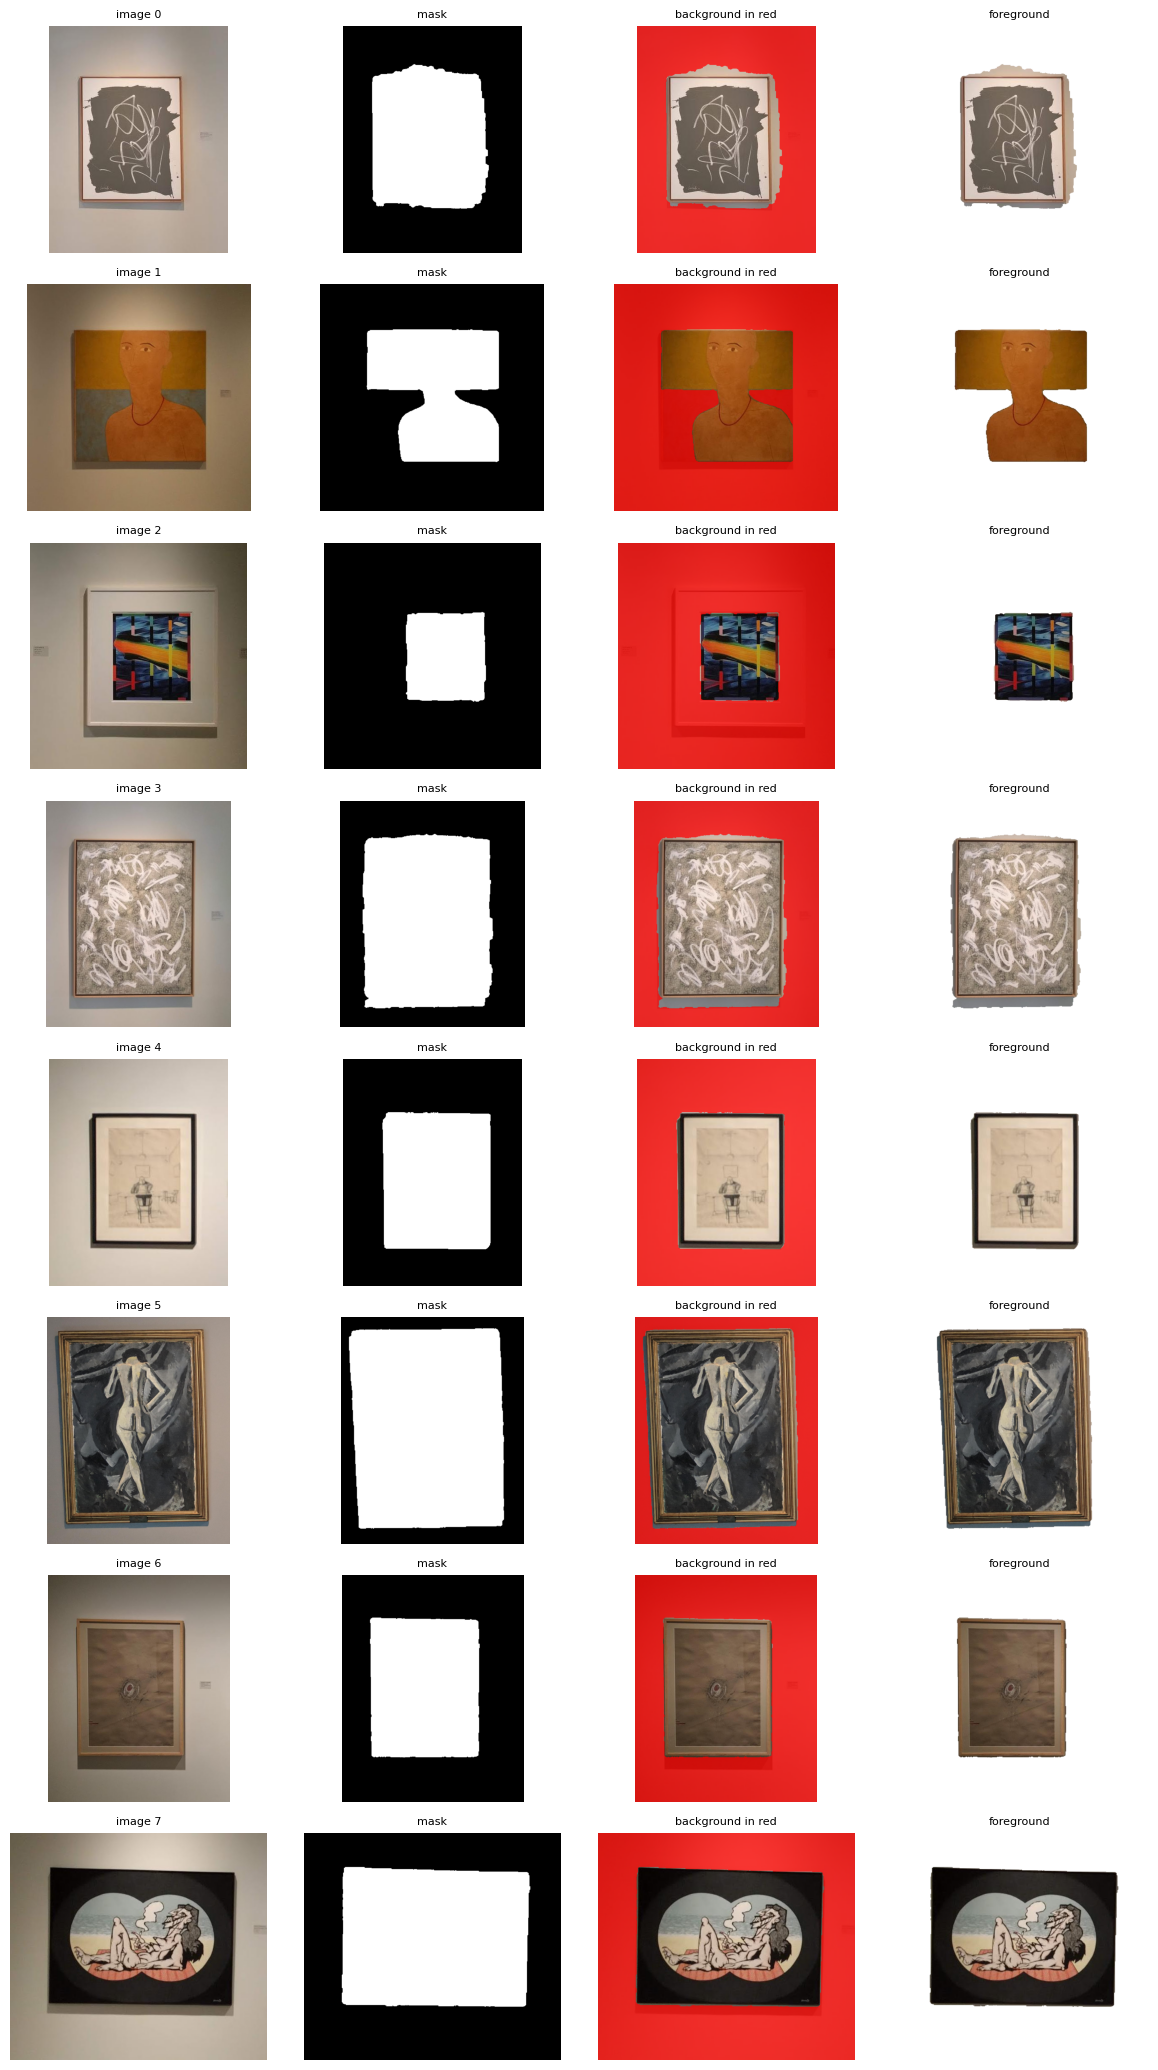

In [19]:
def show_masks(imgs, masks, idx, ncols=4):
    n = len(idx)
    fig, axes = plt.subplots(n, ncols, figsize=(3 * ncols, 2.6 * n))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idx):
        im, m = imgs[i], masks[i]
        rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        overlay = rgb.copy()
        overlay[~m] = (0.25 * overlay[~m] + 0.75 * np.array([255, 0, 0])).astype(np.uint8)
        cut = rgb.copy(); cut[~m] = 255
        for ax, x, t in zip(axes[r], [rgb, m, overlay, cut],
                            [f"image {i}", "mask", "background in red", "foreground"]):
            ax.imshow(x, cmap="gray" if x.ndim == 2 else None); ax.set_title(t, fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

show_masks(qst2_imgs, qst2_masks, list(range(0, min(8, len(qst2_imgs)))))

## Task 4 - Background removal evaluation

The foreground (painting) is the positive class. We evaluate the masks produced by Task 3 on the QSD2 development set, where the PNG files are the ground-truth masks. QST2 has no ground truth and must not be used to tune or evaluate the segmentation.

For each mask we count:
- **TP**: annotation foreground and predicted foreground
- **FP**: annotation background but predicted foreground
- **FN**: annotation foreground but predicted background
- **TN**: annotation background and predicted background

Then $P = TP/(TP+FP)$, $R = TP/(TP+FN)$ and $F_1 = 2PR/(P+R)$. We report the mean score over images (macro) and the score after pooling all pixels (micro).

In [20]:
qsd2 = load_image_dataset(f"{DATA_DIR}/qsd2_w1")
qsd2_imgs = [read(p) for p in qsd2.paths]
qsd2_gt_masks = []

for p, img in zip(qsd2.paths, qsd2_imgs):
    gt_path = p.with_suffix(".png")
    gt = cv2.imread(gt_path.as_posix(), cv2.IMREAD_GRAYSCALE)
    if gt is None:
        raise FileNotFoundError(f"Missing mask: {gt_path}")
    if gt.shape != img.shape[:2]:
        raise ValueError(f"Mask/image size mismatch for {p.name}: {gt.shape} vs {img.shape[:2]}")
    qsd2_gt_masks.append(gt > 127)

qsd2_masks = [foreground_mask(img) for img in qsd2_imgs]
print(len(qsd2_imgs), "QSD2 images and masks loaded")

30 QSD2 images and masks loaded


In [21]:
def mask_counts(annotation, output):
    """Return TP, FP, FN and TN with foreground as the positive class."""
    annotation = np.asarray(annotation, dtype=bool)
    output = np.asarray(output, dtype=bool)
    if annotation.shape != output.shape:
        raise ValueError(f"Mask shapes differ: {annotation.shape} and {output.shape}")
    return {
        "tp": int(np.count_nonzero(annotation & output)),
        "fp": int(np.count_nonzero(~annotation & output)),
        "fn": int(np.count_nonzero(annotation & ~output)),
        "tn": int(np.count_nonzero(~annotation & ~output)),
    }


def scores_from_counts(counts):
    tp, fp, fn = counts["tp"], counts["fp"], counts["fn"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": precision, "recall": recall, "f1": f1}


def evaluate_masks(annotations, outputs):
    if len(annotations) != len(outputs):
        raise ValueError("The number of annotations and outputs must match")

    per_image = []
    totals = {name: 0 for name in ("tp", "fp", "fn", "tn")}
    for i, (annotation, output) in enumerate(zip(annotations, outputs)):
        counts = mask_counts(annotation, output)
        scores = scores_from_counts(counts)
        per_image.append({"query": i, **counts, **scores})
        for name in totals:
            totals[name] += counts[name]

    macro = {
        name: float(np.mean([row[name] for row in per_image]))
        for name in ("precision", "recall", "f1")
    }
    micro = scores_from_counts(totals)
    return {"macro": macro, "micro": micro, "totals": totals}, per_image


task4_summary, task4_per_image = evaluate_masks(qsd2_gt_masks, qsd2_masks)
for averaging in ("macro", "micro"):
    s = task4_summary[averaging]
    print(f"{averaging:>5}: precision {s['precision']:.3f}  recall {s['recall']:.3f}  F1 {s['f1']:.3f}")

f1_values = np.array([row["f1"] for row in task4_per_image])
print("per-image F1: min %.3f  median %.3f  max %.3f" % tuple(np.percentile(f1_values, [0, 50, 100])))

macro: precision 0.955  recall 0.978  F1 0.965
micro: precision 0.979  recall 0.989  F1 0.984
per-image F1: min 0.874  median 0.978  max 0.996


### Visual inspection of the weakest masks

The error image uses green for true-positive foreground, red for false-positive background, blue for missed foreground, and black for true-negative background. Looking at the lowest-F1 cases prevents a high average from hiding a catastrophic segmentation.

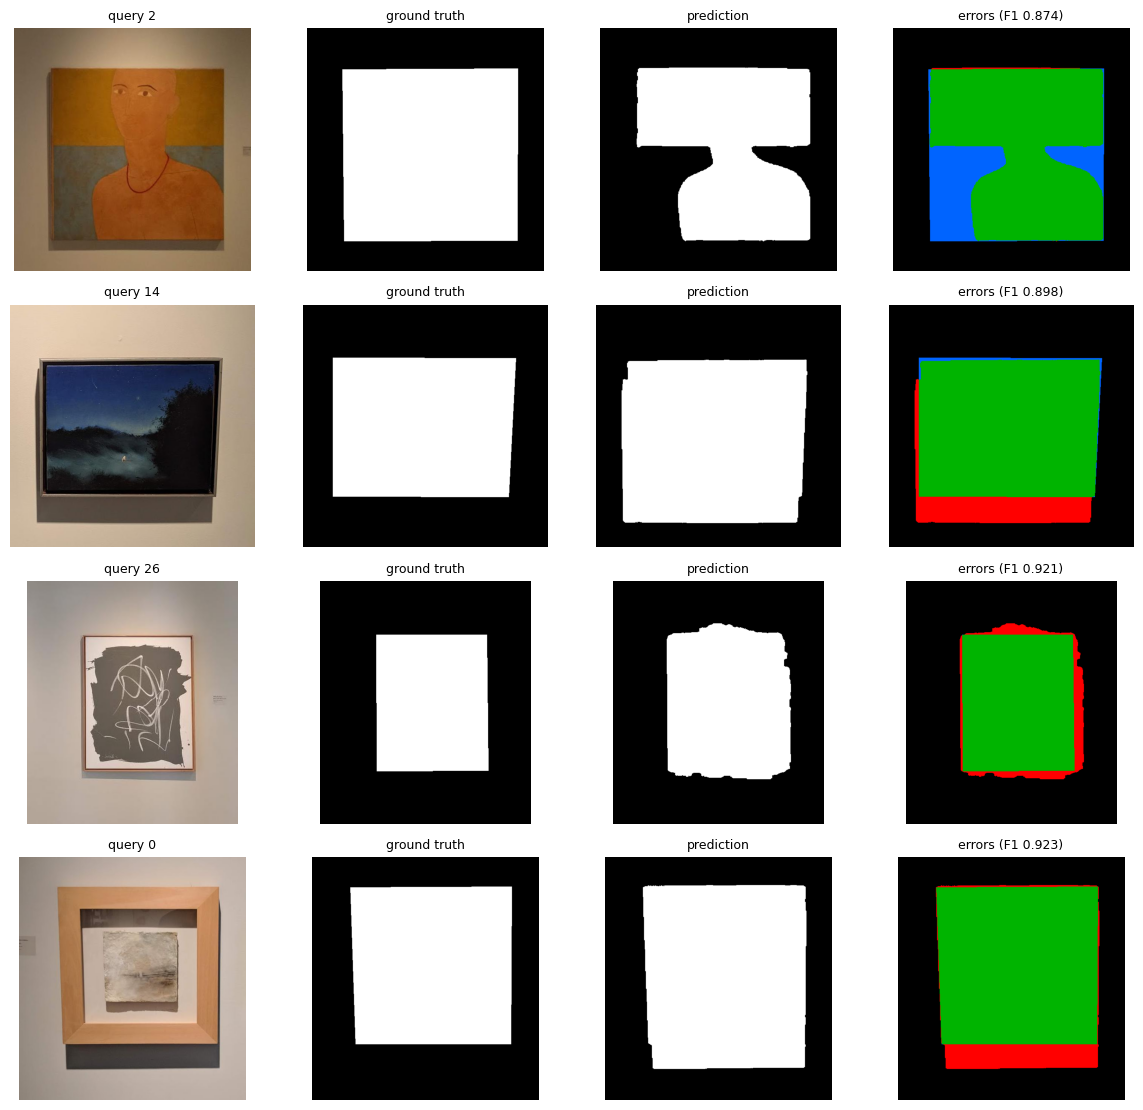

In [22]:
def show_mask_evaluation(imgs, annotations, outputs, indices):
    fig, axes = plt.subplots(len(indices), 4, figsize=(12, 2.8 * len(indices)))
    axes = np.atleast_2d(axes)
    for row, i in enumerate(indices):
        rgb = cv2.cvtColor(imgs[i], cv2.COLOR_BGR2RGB)
        gt, pred = annotations[i], outputs[i]
        error = np.zeros((*gt.shape, 3), dtype=np.uint8)
        error[gt & pred] = (0, 180, 0)       # TP: green
        error[~gt & pred] = (255, 0, 0)      # FP: red
        error[gt & ~pred] = (0, 100, 255)    # FN: blue

        score = task4_per_image[i]["f1"]
        for ax, value, title in zip(
            axes[row], [rgb, gt, pred, error],
            [f"query {i}", "ground truth", "prediction", f"errors (F1 {score:.3f})"],
        ):
            ax.imshow(value, cmap="gray" if value.ndim == 2 else None)
            ax.set_title(title, fontsize=9)
            ax.axis("off")
    plt.tight_layout(); plt.show()


worst_masks = np.argsort(f1_values)[:4].tolist()
show_mask_evaluation(qsd2_imgs, qsd2_gt_masks, qsd2_masks, worst_masks)

Conclusion (Task 4): On QSD2, the current colour-based method obtains macro precision **0.955**, recall **0.978** and F1 **0.965**. Pooling all pixels gives precision **0.979**, recall **0.989** and F1 **0.984**. Recall is slightly higher than precision, so the method more often includes a small amount of wall/frame than removes painting pixels. Macro scores are the fairer per-query summary because micro scores give larger images more weight.

## Task 5 - Retrieval on QSD2 after background removal

For every QSD2 image we remove the background, compute the Task 2 descriptor only on predicted foreground pixels, retrieve the ten closest database paintings and return their integer IDs. only the retrieval correspondences are evaluated.

We keep the selected Task 2 method (5x5 block Lab histograms, 48 bins, $\sigma=0.5$, weights 0.125/0.5/0.375 and Hellinger distance). The database uses complete images; only the QSD2 query descriptors are masked.

In [23]:
def retrieve_from_features(query_features, database_features, database_ids, k=10):
    results = []
    for query in query_features:
        order = np.argsort(hellinger(query, database_features), kind="stable")[:k]
        results.append([int(database_ids[i]) for i in order])
    return results


qsd2_ground_truth = load_ground_truth(f"{DATA_DIR}/qsd2_w1/gt_corresps.pkl")

# Same 5x5 descriptor selected in Task 2. Database paintings have no removable wall.
task5_database_features = np.array([
    descriptor_masked(img, levels=(5,)) for img in db_imgs
])
task5_masked_features = np.array([
    descriptor_masked(img, mask, levels=(5,))
    for img, mask in zip(qsd2_imgs, qsd2_masks)
])
task5_results = retrieve_from_features(
    task5_masked_features, task5_database_features, train_dataset.ids, k=10
)

task5_map1 = map_at_k(task5_results, qsd2_ground_truth, 1)
task5_map5 = map_at_k(task5_results, qsd2_ground_truth, 5)
print(f"masked QSD2: mAP@1 {task5_map1:.3f}  mAP@5 {task5_map5:.3f}")
print("first five top-10 correspondences:")
for query_id, result in zip(qsd2.ids[:5], task5_results[:5]):
    print(f"{query_id:05d}: {result}")

masked QSD2: mAP@1 0.700  mAP@5 0.768
first five top-10 correspondences:
00000: [40, 100, 31, 235, 232, 20, 16, 271, 215, 161]
00001: [219, 179, 216, 10, 126, 240, 279, 238, 286, 128]
00002: [251, 172, 19, 142, 250, 107, 156, 76, 239, 167]
00003: [25, 104, 200, 154, 143, 149, 66, 29, 105, 137]
00004: [22, 205, 16, 12, 137, 202, 51, 194, 93, 252]


### Does background removal help retrieval?

For a controlled comparison, we use the same descriptor and distance but compute QSD2 descriptors without masks. This isolates the value of background removal.

In [24]:
task5_unmasked_features = np.array([
    descriptor_masked(img, mask=None, levels=(5,)) for img in qsd2_imgs
])
task5_unmasked_results = retrieve_from_features(
    task5_unmasked_features, task5_database_features, train_dataset.ids, k=10
)

print("                         mAP@1  mAP@5")
print("without background mask  %.3f  %.3f" % (
    map_at_k(task5_unmasked_results, qsd2_ground_truth, 1),
    map_at_k(task5_unmasked_results, qsd2_ground_truth, 5),
))
print("with predicted mask       %.3f  %.3f" % (task5_map1, task5_map5))

                         mAP@1  mAP@5
without background mask  0.333  0.383
with predicted mask       0.700  0.768


### Retrieval examples and failure analysis

Green borders mark correct database paintings and red borders mark incorrect results. We inspect queries where the correct painting is not ranked first.

query  0  gt id 100  correct image at rank: 2
query  2  gt id 250  correct image at rank: 5
query  7  gt id 184  correct image at rank: 2
query 10  gt id 128  correct image at rank: 8
query 18  gt id  86  correct image at rank: None
query 20  gt id  41  correct image at rank: None
query 23  gt id  58  correct image at rank: 3
query 26  gt id 258  correct image at rank: None
query 28  gt id  12  correct image at rank: 2

failing at rank 1: 9 of 30


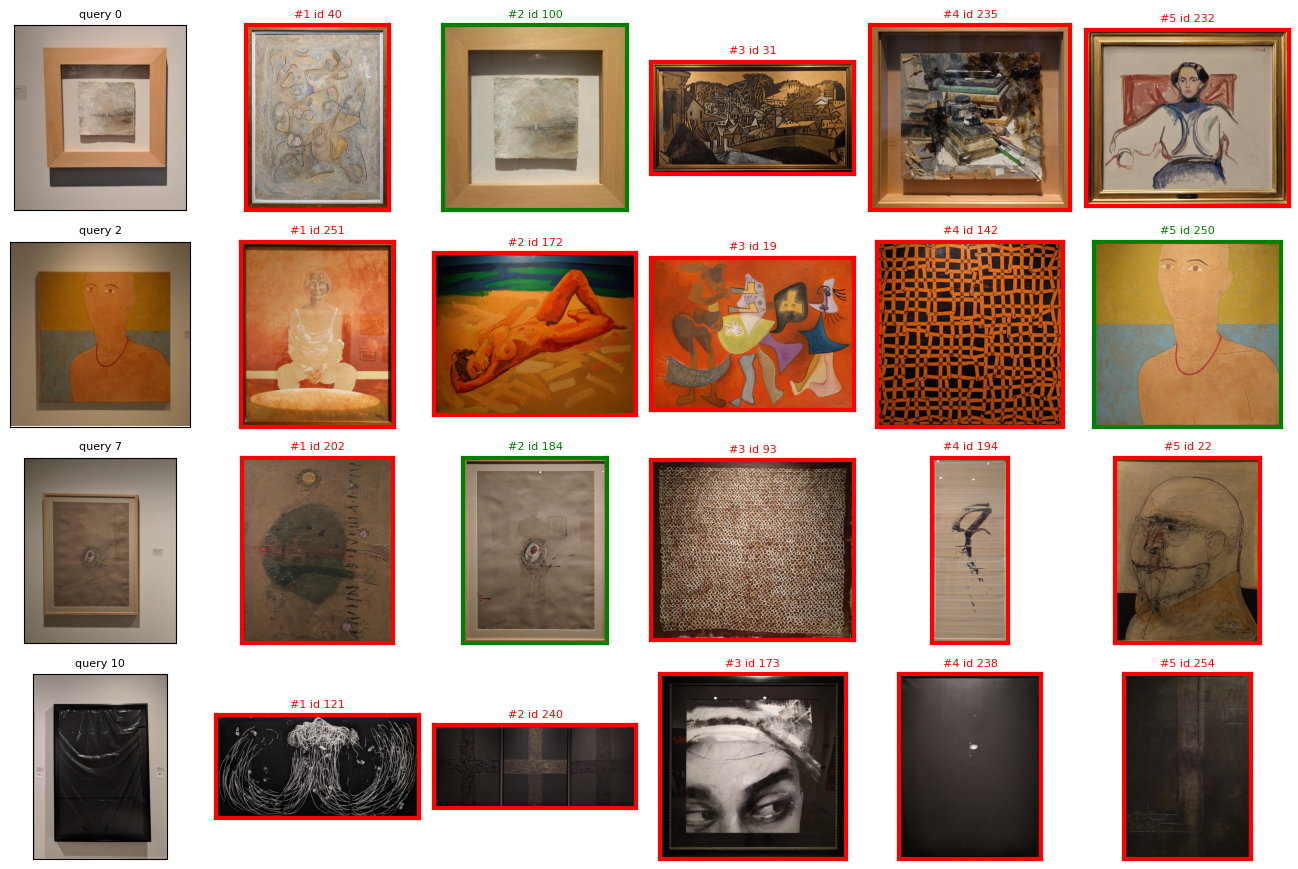

In [25]:
task5_fails = []
for i, (result, relevant) in enumerate(zip(task5_results, qsd2_ground_truth)):
    rank = next((r for r, image_id in enumerate(result, 1) if image_id in relevant), None)
    if rank != 1:
        task5_fails.append(i)
        print(f"query {i:>2}  gt id {relevant[0]:>3}  correct image at rank: {rank}")

print("\nfailing at rank 1:", len(task5_fails), "of", len(qsd2_ground_truth))
show_retrievals(
    task5_results, qsd2_imgs, db_imgs, train_dataset.ids,
    qsd2_ground_truth, task5_fails[:4], k=5
)

Conclusion (Task 5): Foreground-only retrieval obtains **mAP@1 0.700** and **mAP@5 0.768** on QSD2, compared with **0.333 / 0.383** when the same queries are used without background masks. Removing the wall and aligning the 5x5 grid to the predicted painting region therefore produces the main improvement. Ten database IDs per query are available in `task5_results`.

## Task 6 - Blind QST1 and QST2 submissions

For every QST1-W2 and QST2-W2 query, submit the ten best database image IDs as a Python list of lists. Every ID must be an integer and rows must follow sorted query-filename order. QST2 also requires one binary PNG mask per query with the same stem as the JPG (`00001.jpg` becomes `00001.png`).

We freeze the methods selected using the development sets:
- **QST1:** the Task 2 5x5 block Lab descriptor on the complete cropped image.
- **QST2:** the Task 3 colour mask followed by the Task 5 foreground-only 5x5 descriptor.

In [26]:
qst1_w2 = load_image_dataset(f"{DATA_DIR}/qst_w2/qst1_w2")
qst2_w2 = load_image_dataset(f"{DATA_DIR}/qst_w2/qst2_w2")
qst1_w2_imgs = [read(p) for p in qst1_w2.paths]
qst2_w2_imgs = [read(p) for p in qst2_w2.paths]

# QST1 uses the exact complete-image descriptor selected in Task 2.
qst1_database_features = np.array([descriptor(img, levels=(5,)) for img in db_imgs])
qst1_features = np.array([descriptor(img, levels=(5,)) for img in qst1_w2_imgs])
qst1_results = retrieve_from_features(
    qst1_features, qst1_database_features, train_dataset.ids, k=10
)

# QST2 uses predicted foreground masks and the method validated in Task 5.
qst2_w2_masks = [foreground_mask(img) for img in qst2_w2_imgs]
qst2_features = np.array([
    descriptor_masked(img, mask, levels=(5,))
    for img, mask in zip(qst2_w2_imgs, qst2_w2_masks)
])
qst2_results = retrieve_from_features(
    qst2_features, task5_database_features, train_dataset.ids, k=10
)

print(f"QST1 queries: {len(qst1_results)}; QST2 queries: {len(qst2_results)}")
print("QST1 first row:", qst1_results[0])
print("QST2 first row:", qst2_results[0])

QST1 queries: 30; QST2 queries: 30
QST1 first row: [194, 184, 212, 205, 97, 252, 93, 270, 226, 148]
QST2 first row: [35, 106, 5, 18, 125, 146, 182, 47, 272, 68]


### Write the required files

The result pickles contain only the required list of lists. QST2 masks are stored as 8-bit images whose values are exactly 0 for background and 255 for painting.

In [27]:
SUBMISSION_ROOT = DATA_DIR.parent / "submissions" / "week2"
QST1_METHOD_DIR = SUBMISSION_ROOT / "QST1" / "method1"
QST2_METHOD_DIR = SUBMISSION_ROOT / "QST2" / "method1"


def save_rankings(rankings, output_path, expected_queries, k=10):
    clean = [[int(image_id) for image_id in row] for row in rankings]
    if len(clean) != expected_queries:
        raise ValueError(f"Expected {expected_queries} query rows, got {len(clean)}")
    if any(len(row) != k for row in clean):
        raise ValueError(f"Every query must contain exactly {k} results")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("wb") as stream:
        pickle.dump(clean, stream)


def save_submission_masks(query_paths, masks, output_dir):
    if len(query_paths) != len(masks):
        raise ValueError("The number of QST2 images and masks must match")
    output_dir.mkdir(parents=True, exist_ok=True)
    for query_path, mask in zip(query_paths, masks):
        output_path = output_dir / f"{query_path.stem}.png"
        binary = np.asarray(mask, dtype=np.uint8) * 255
        if not cv2.imwrite(output_path.as_posix(), binary):
            raise OSError(f"Could not write {output_path}")


save_rankings(qst1_results, QST1_METHOD_DIR / "result.pkl", len(qst1_w2), k=10)
save_rankings(qst2_results, QST2_METHOD_DIR / "result.pkl", len(qst2_w2), k=10)
save_submission_masks(qst2_w2.paths, qst2_w2_masks, QST2_METHOD_DIR)
print("Submission files written to", SUBMISSION_ROOT)

Submission files written to /Users/femiloye/Desktop/MCV/Materials/C1/project/submissions/week2


In [28]:
def validate_rankings(result_path, query_dataset, database_ids, k=10):
    with result_path.open("rb") as stream:
        rankings = pickle.load(stream)

    valid_database_ids = {int(image_id) for image_id in database_ids}
    if not isinstance(rankings, list) or len(rankings) != len(query_dataset):
        raise ValueError(f"{result_path}: expected {len(query_dataset)} query rows")
    for row_number, row in enumerate(rankings):
        if not isinstance(row, list) or len(row) != k:
            raise ValueError(f"{result_path}: row {row_number} does not have {k} results")
        if not all(type(image_id) is int for image_id in row):
            raise TypeError(f"{result_path}: row {row_number} contains a non-integer ID")
        if len(set(row)) != k:
            raise ValueError(f"{result_path}: row {row_number} contains duplicate IDs")
        unknown = set(row) - valid_database_ids
        if unknown:
            raise ValueError(f"{result_path}: unknown database IDs {sorted(unknown)}")
    return rankings


def validate_submission_masks(query_dataset, mask_dir):
    expected_names = {f"{path.stem}.png" for path in query_dataset.paths}
    actual_names = {path.name for path in mask_dir.glob("*.png")}
    if actual_names != expected_names:
        raise ValueError(
            f"Mask filenames differ: missing={sorted(expected_names - actual_names)}, "
            f"extra={sorted(actual_names - expected_names)}"
        )

    for query_path in query_dataset.paths:
        image = cv2.imread(query_path.as_posix(), cv2.IMREAD_COLOR)
        mask_path = mask_dir / f"{query_path.stem}.png"
        mask = cv2.imread(mask_path.as_posix(), cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise FileNotFoundError(f"Could not reopen {query_path} or {mask_path}")
        if mask.shape != image.shape[:2]:
            raise ValueError(f"{mask_path}: shape {mask.shape} != {image.shape[:2]}")
        values = set(np.unique(mask).tolist())
        if not values.issubset({0, 255}):
            raise ValueError(f"{mask_path}: mask is not binary; values={sorted(values)}")
    return len(actual_names)


saved_qst1 = validate_rankings(
    QST1_METHOD_DIR / "result.pkl", qst1_w2, train_dataset.ids, k=10
)
saved_qst2 = validate_rankings(
    QST2_METHOD_DIR / "result.pkl", qst2_w2, train_dataset.ids, k=10
)
saved_mask_count = validate_submission_masks(qst2_w2, QST2_METHOD_DIR)

print("VALIDATION PASSED")
print(f"QST1: {len(saved_qst1)} rows x {len(saved_qst1[0])} results")
print(f"QST2: {len(saved_qst2)} rows x {len(saved_qst2[0])} results")
print(f"QST2: {saved_mask_count} correctly named binary masks")
print(f"Query order: {qst1_w2.paths[0].name} ... {qst1_w2.paths[-1].name}")

VALIDATION PASSED
QST1: 30 rows x 10 results
QST2: 30 rows x 10 results
QST2: 30 correctly named binary masks
Query order: 00000.jpg ... 00029.jpg


### Final visual spot-check


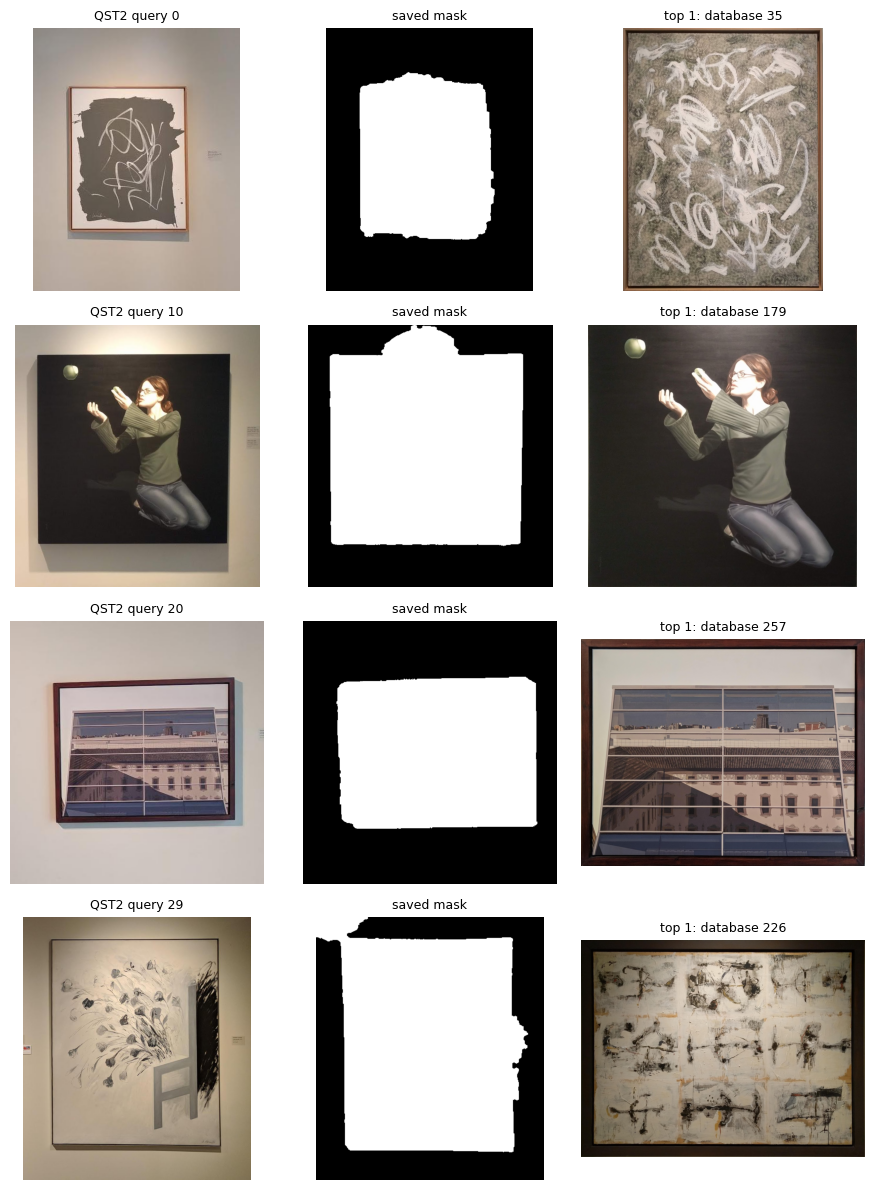

In [29]:
def show_submission_examples(query_imgs, query_masks, results, database_imgs, database_ids, indices):
    id_to_index = {int(image_id): i for i, image_id in enumerate(database_ids)}
    fig, axes = plt.subplots(len(indices), 3, figsize=(9, 3 * len(indices)))
    axes = np.atleast_2d(axes)
    for row, i in enumerate(indices):
        top1_id = results[i][0]
        values = [
            cv2.cvtColor(query_imgs[i], cv2.COLOR_BGR2RGB),
            query_masks[i],
            cv2.cvtColor(database_imgs[id_to_index[top1_id]], cv2.COLOR_BGR2RGB),
        ]
        titles = [f"QST2 query {i}", "saved mask", f"top 1: database {top1_id}"]
        for ax, value, title in zip(axes[row], values, titles):
            ax.imshow(value, cmap="gray" if value.ndim == 2 else None)
            ax.set_title(title, fontsize=9)
            ax.axis("off")
    plt.tight_layout(); plt.show()


show_submission_examples(
    qst2_w2_imgs, qst2_w2_masks, saved_qst2, db_imgs, train_dataset.ids, [0, 10, 20, 29]
)